In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, log_loss

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("nc_uplift_poc_4000.csv")

print("SHAPE:",df.shape)
df.head()

SHAPE: (4000, 26)


,customer_id,campaign_id,target_category,age,tenure_days,orders_30d,orders_90d,aov,nc_orders_90d,nc_orders_180d,...,wishlist_30d,cart_abandon_rate,discount_usage_rate,campaign_engagement_rate,app_sessions_30d,weekend_order_share,discount_pct,treatment,nc_purchase_14d,nc_gmv_14d
0,100001,NC_AUDIO_SEP,Electronics,35,949,3,5,789.0,1,2,...,1,0.801,0.613,0.470,10,0.270,20,1,0,0.0
1,100002,NC_AUDIO_SEP,Smartwatch,30,295,1,11,520.0,1,1,...,1,0.633,0.594,0.064,16,0.755,15,0,0,0.0
2,100003,NC_ELECTRONICS_SEP,Earbuds,36,1173,5,7,399.0,0,3,...,0,0.731,0.669,0.171,13,0.521,20,1,1,979.0
3,100004,NC_AUDIO_SEP,Smartwatch,43,741,2,10,417.0,0,1,...,0,0.848,0.578,0.349,15,0.610,15,0,1,764.0
4,100005,NC_AUDIO_SEP,Earbuds,29,1301,5,12,794.0,1,4,...,0,0.519,0.510,0.254,12,0.306,15,1,1,2745.0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 26 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               4000 non-null   int64  
 1   campaign_id               4000 non-null   object 
 2   target_category           4000 non-null   object 
 3   age                       4000 non-null   int64  
 4   tenure_days               4000 non-null   int64  
 5   orders_30d                4000 non-null   int64  
 6   orders_90d                4000 non-null   int64  
 7   aov                       4000 non-null   float64
 8   nc_orders_90d             4000 non-null   int64  
 9   nc_orders_180d            4000 non-null   int64  
 10  nc_gmv_180d               4000 non-null   float64
 11  days_since_nc_purchase    4000 non-null   int64  
 12  nc_category_share         4000 non-null   float64
 13  product_views_30d         4000 non-null   int64  
 14  searches

In [4]:
missing = (
    df.isnull()
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

missing

customer_id                 0.0
campaign_id                 0.0
nc_purchase_14d             0.0
treatment                   0.0
discount_pct                0.0
weekend_order_share         0.0
app_sessions_30d            0.0
campaign_engagement_rate    0.0
discount_usage_rate         0.0
cart_abandon_rate           0.0
wishlist_30d                0.0
add_to_cart_30d             0.0
searches_30d                0.0
product_views_30d           0.0
nc_category_share           0.0
days_since_nc_purchase      0.0
nc_gmv_180d                 0.0
nc_orders_180d              0.0
nc_orders_90d               0.0
aov                         0.0
orders_90d                  0.0
orders_30d                  0.0
tenure_days                 0.0
age                         0.0
target_category             0.0
nc_gmv_14d                  0.0
dtype: float64

In [5]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customers:", df["customer_id"].duplicated().sum())

Duplicate rows: 0
Duplicate customers: 0


In [9]:
df['treatment'].value_counts()

0    2013
1    1987
Name: treatment, dtype: int64

In [10]:
treatment_summary = (
    df.groupby("treatment")
      .agg(
          customers=("customer_id", "count"),
          conversion=("nc_purchase_14d", "mean"),
          gmv=("nc_gmv_14d", "sum")
      )
)

treatment_summary

,customers,conversion,gmv
treatment,,,
0,2013,0.187283,382095.0
1,1987,0.253649,540921.0


In [11]:
treatment_summary["conversion_pct"] = (
    treatment_summary["conversion"] * 100
)

treatment_summary

,customers,conversion,gmv,conversion_pct
treatment,,,,
0,2013,0.187283,382095.0,18.728266
1,1987,0.253649,540921.0,25.364872


In [12]:
control_conversion = df.loc[
    df["treatment"] == 0,
    "nc_purchase_14d"
].mean()

treatment_conversion = df.loc[
    df["treatment"] == 1,
    "nc_purchase_14d"
].mean()

ate = treatment_conversion - control_conversion

print(f"Control conversion:   {control_conversion:.4f}")
print(f"Treatment conversion: {treatment_conversion:.4f}")
print(f"ATE:                   {ate:.4f}")
print(f"ATE percentage points: {ate * 100:.2f} pp")

Control conversion:   0.1873
Treatment conversion: 0.2536
ATE:                   0.0664
ATE percentage points: 6.64 pp


In [13]:
feature_cols = [
    "age",
    "tenure_days",
    "orders_30d",
    "orders_90d",
    "aov",
    "nc_orders_90d",
    "nc_orders_180d",
    "nc_gmv_180d",
    "days_since_nc_purchase",
    "nc_category_share",
    "product_views_30d",
    "searches_30d",
    "add_to_cart_30d",
    "wishlist_30d",
    "cart_abandon_rate",
    "discount_usage_rate",
    "campaign_engagement_rate",
    "app_sessions_30d",
    "weekend_order_share",
    "discount_pct",
    "target_category",
    "campaign_id"
]

X = df[feature_cols]

y = df["nc_purchase_14d"]

treatment = df["treatment"]

In [16]:
train_idx, test_idx = train_test_split(
    np.arange(len(df)),
    test_size=0.30,
    random_state=42,
    stratify=df["treatment"]
)

train = df.iloc[train_idx].copy()
test = df.iloc[test_idx].copy()

print("Train:", train.shape)
print("Test :", test.shape)

Train: (2800, 26)
Test : (1200, 26)


In [18]:
train_treated = train[train["treatment"] == 1].copy()
train_control = train[train["treatment"] == 0].copy()

print("Treated:", len(train_treated))
print("Control:", len(train_control))

Treated: 1391
Control: 1409


In [19]:
categorical_features = [
    "target_category",
    "campaign_id"
]

numerical_features = [
    col for col in feature_cols
    if col not in categorical_features
]

In [20]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
        (
            "num",
            "passthrough",
            numerical_features
        )
    ]
)

In [21]:
treatment_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            HistGradientBoostingClassifier(
                max_iter=200,
                learning_rate=0.05,
                max_leaf_nodes=15,
                l2_regularization=1.0,
                random_state=42
            )
        )
    ]
)

In [22]:
treatment_model.fit(
    train_treated[feature_cols],
    train_treated["nc_purchase_14d"]
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['target_category',
                                                   'campaign_id']),
                                                 ('num', 'passthrough',
                                                  ['age', 'tenure_days',
                                                   'orders_30d', 'orders_90d',
                                                   'aov', 'nc_orders_90d',
                                                   'nc_orders_180d',
                                                   'nc_gmv_180d',
                                                   'days_since_nc_purchase',
                                                   'nc_category_share',
                                                   'product_views_30d',
                                                   'searches_30d',
                                                   'add_to_cart_30d',
                                                   'wishlist_30d',
                                                   'cart_abandon_rate',
                                                   'discount_usage_rate',
                                                   'campaign_engagement_rate',
                                                   'app_sessions_30d',
                                                   'weekend_order_share',
                                                   'discount_pct'])])),
                ('model',
                 HistGradientBoostingClassifier(l2_regularization=1.0,
                                                learning_rate=0.05,
                                                max_iter=200, max_leaf_nodes=15,
                                                random_state=42))])

In [23]:
control_preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
        (
            "num",
            "passthrough",
            numerical_features
        )
    ]
)

In [24]:
control_model = Pipeline(
    steps=[
        ("preprocessor", control_preprocessor),
        (
            "model",
            HistGradientBoostingClassifier(
                max_iter=200,
                learning_rate=0.05,
                max_leaf_nodes=15,
                l2_regularization=1.0,
                random_state=42
            )
        )
    ]
)

In [25]:
control_model.fit(
    train_control[feature_cols],
    train_control["nc_purchase_14d"]
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['target_category',
                                                   'campaign_id']),
                                                 ('num', 'passthrough',
                                                  ['age', 'tenure_days',
                                                   'orders_30d', 'orders_90d',
                                                   'aov', 'nc_orders_90d',
                                                   'nc_orders_180d',
                                                   'nc_gmv_180d',
                                                   'days_since_nc_purchase',
                                                   'nc_category_share',
                                                   'product_views_30d',
                                                   'searches_30d',
                                                   'add_to_cart_30d',
                                                   'wishlist_30d',
                                                   'cart_abandon_rate',
                                                   'discount_usage_rate',
                                                   'campaign_engagement_rate',
                                                   'app_sessions_30d',
                                                   'weekend_order_share',
                                                   'discount_pct'])])),
                ('model',
                 HistGradientBoostingClassifier(l2_regularization=1.0,
                                                learning_rate=0.05,
                                                max_iter=200, max_leaf_nodes=15,
                                                random_state=42))])

In [26]:
test["p_treatment"] = treatment_model.predict_proba(
    test[feature_cols]
)[:, 1]

test["p_control"] = control_model.predict_proba(
    test[feature_cols]
)[:, 1]

In [27]:
test["uplift_score"] = (
    test["p_treatment"]
    - test["p_control"]
)

In [28]:
test

,customer_id,campaign_id,target_category,age,tenure_days,orders_30d,orders_90d,aov,nc_orders_90d,nc_orders_180d,...,campaign_engagement_rate,app_sessions_30d,weekend_order_share,discount_pct,treatment,nc_purchase_14d,nc_gmv_14d,p_treatment,p_control,uplift_score
2782,102783,NC_ELECTRONICS_SEP,Smartwatch,21,734,5,8,680.0,1,1,...,0.207,14,0.455,20,0,0,0.0,0.298357,0.259746,0.038611
2964,102965,NC_ELECTRONICS_SEP,Earbuds,41,130,6,12,989.0,0,2,...,0.251,10,0.850,20,1,0,0.0,0.319663,0.202079,0.117585
2584,102585,NC_GADGETS_SEP,Power Bank,40,1206,3,4,400.0,1,1,...,0.323,13,0.485,15,1,0,0.0,0.162559,0.213566,-0.051008
412,100413,NC_ELECTRONICS_SEP,Power Bank,19,344,1,10,363.0,0,2,...,0.119,8,0.882,20,0,1,782.0,0.306696,0.323367,-0.016671
3381,103382,NC_GADGETS_SEP,Electronics,41,340,1,12,844.0,1,3,...,0.376,9,0.607,25,1,0,0.0,0.569875,0.155487,0.414388
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3100,103101,NC_ELECTRONICS_SEP,Earbuds,25,1314,5,8,614.0,0,0,...,0.200,15,0.356,30,1,1,938.0,0.039849,0.020906,0.018943
1406,101407,NC_GADGETS_SEP,Power Bank,20,833,4,7,937.0,1,1,...,0.100,20,0.639,30,0,0,0.0,0.176761,0.061841,0.114920
767,100768,NC_AUDIO_SEP,Power Bank,45,114,5,8,279.0,0,0,...,0.165,11,0.282,20,0,0,0.0,0.027395,0.022528,0.004868
3486,103487,NC_ELECTRONICS_SEP,Smartwatch,43,1380,4,4,406.0,0,1,...,0.092,9,0.323,30,1,0,0.0,0.196301,0.099344,0.096957


In [30]:
test_sorted = test.sort_values(
    "uplift_score",
    ascending=False
)

test_sorted[
    [
        "customer_id",
        "p_treatment",
        "p_control",
        "uplift_score",
        "treatment",
        "nc_purchase_14d"
    ]
].head(20)

,customer_id,p_treatment,p_control,uplift_score,treatment,nc_purchase_14d
2369,102370,0.793450,0.137765,0.655686,1,0
31,100032,0.695376,0.048263,0.647113,0,0
3646,103647,0.729683,0.099439,0.630244,1,1
184,100185,0.656379,0.064527,0.591852,1,0
3217,103218,0.643985,0.059459,0.584526,0,1
1944,101945,0.618867,0.042380,0.576487,0,1
334,100335,0.654824,0.096145,0.558679,0,1
489,100490,0.638767,0.089082,0.549685,0,1
3991,103992,0.633205,0.096780,0.536425,1,0
2075,102076,0.597382,0.066424,0.530958,1,0


In [31]:
test["propensity_score"] = test["p_treatment"]

In [32]:
uplift_targeted = test.sort_values(
    "uplift_score",
    ascending=False
)

propensity_targeted = test.sort_values(
    "propensity_score",
    ascending=False
)

In [33]:
test["uplift_percentile"] = (
    test["uplift_score"]
    .rank(pct=True)
)

test["uplift_segment"] = pd.cut(
    test["uplift_percentile"],
    bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0],
    labels=[
        "Bottom 20%",
        "20-40%",
        "40-60%",
        "60-80%",
        "Top 20%"
    ]
)

In [34]:
test[
    [
        "customer_id",
        "uplift_score",
        "uplift_segment"
    ]
].head()

,customer_id,uplift_score,uplift_segment
2782,102783,0.038611,20-40%
2964,102965,0.117585,60-80%
2584,102585,-0.051008,Bottom 20%
412,100413,-0.016671,20-40%
3381,103382,0.414388,Top 20%


In [35]:
segment_summary = (
    test.groupby("uplift_segment", observed=True)
        .agg(
            customers=("customer_id", "count"),
            avg_uplift=("uplift_score", "mean"),
            avg_treatment_prob=("p_treatment", "mean"),
            avg_control_prob=("p_control", "mean")
        )
        .reset_index()
)

segment_summary

,uplift_segment,customers,avg_uplift,avg_treatment_prob,avg_control_prob
0,Bottom 20%,240,-0.128821,0.178670,0.307491
1,20-40%,240,0.019439,0.132974,0.113535
2,40-60%,240,0.081999,0.181091,0.099092
3,60-80%,240,0.160201,0.261410,0.101209
4,Top 20%,240,0.322184,0.426300,0.104116


In [36]:
segment_conversion = (
    test.groupby(
        ["uplift_segment", "treatment"],
        observed=True
    )
    .agg(
        customers=("customer_id", "count"),
        conversions=("nc_purchase_14d", "sum"),
        conversion=("nc_purchase_14d", "mean")
    )
    .reset_index()
)

segment_conversion

,uplift_segment,treatment,customers,conversions,conversion
0,Bottom 20%,0,116,37,0.318966
1,Bottom 20%,1,124,31,0.250000
2,20-40%,0,119,23,0.193277
3,20-40%,1,121,39,0.322314
4,40-60%,0,124,19,0.153226
5,40-60%,1,116,28,0.241379
6,60-80%,0,119,25,0.210084
7,60-80%,1,121,25,0.206612
8,Top 20%,0,126,36,0.285714
9,Top 20%,1,114,35,0.307018


In [37]:
conversion_pivot = (
    segment_conversion
    .pivot(
        index="uplift_segment",
        columns="treatment",
        values="conversion"
    )
    .rename(columns={
        0: "control_conversion",
        1: "treatment_conversion"
    })
)

conversion_pivot["observed_uplift"] = (
    conversion_pivot["treatment_conversion"]
    - conversion_pivot["control_conversion"]
)

conversion_pivot

treatment,control_conversion,treatment_conversion,observed_uplift
uplift_segment,,,
Bottom 20%,0.318966,0.250000,-0.068966
20-40%,0.193277,0.322314,0.129037
40-60%,0.153226,0.241379,0.088154
60-80%,0.210084,0.206612,-0.003472
Top 20%,0.285714,0.307018,0.021303


In [38]:
qini_df = test.sort_values(
    "uplift_score",
    ascending=False
).reset_index(drop=True)

In [39]:
qini_df["rank"] = np.arange(1, len(qini_df) + 1)

qini_df["treated_count"] = (
    qini_df["treatment"]
    .cumsum()
)

qini_df["control_count"] = (
    (1 - qini_df["treatment"])
    .cumsum()
)

qini_df["treated_conversions"] = (
    qini_df["treatment"]
    * qini_df["nc_purchase_14d"]
).cumsum()

qini_df["control_conversions"] = (
    (1 - qini_df["treatment"])
    * qini_df["nc_purchase_14d"]
).cumsum()

In [40]:
qini_df["incremental_conversions"] = (
    qini_df["treated_conversions"]
    -
    qini_df["control_conversions"]
    *
    (
        qini_df["treated_count"]
        /
        qini_df["control_count"].replace(0, np.nan)
    )
)

In [41]:
qini_df["population_fraction"] = (
    qini_df["rank"] / len(qini_df)
)

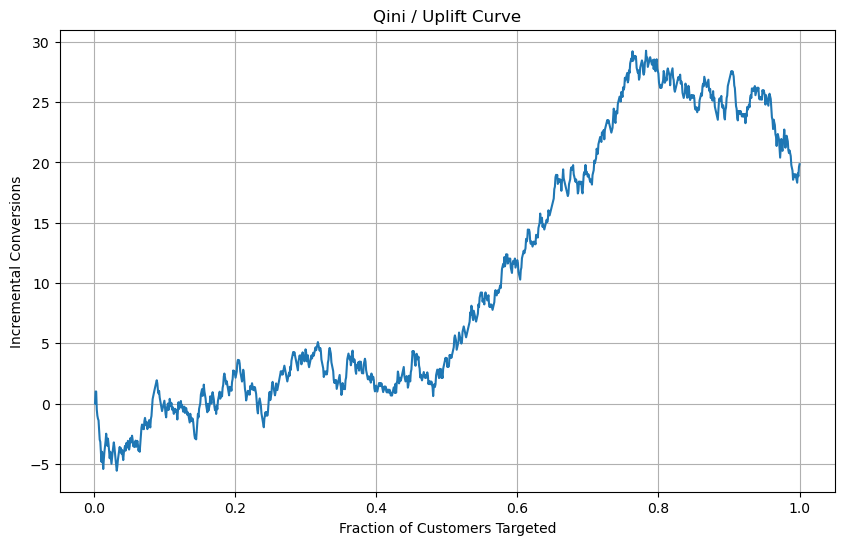

In [42]:
plt.figure(figsize=(10, 6))

plt.plot(
    qini_df["population_fraction"],
    qini_df["incremental_conversions"]
)

plt.xlabel("Fraction of Customers Targeted")
plt.ylabel("Incremental Conversions")
plt.title("Qini / Uplift Curve")

plt.grid(True)
plt.show()

In [45]:
qini_coefficient = np.trapz(
    qini_df["incremental_conversions"],
    qini_df["population_fraction"]
)

print("Qini coefficient:", qini_coefficient)

Qini coefficient: nan


In [49]:
print(qini_df.isna().sum())
print(np.isfinite(qini_df["incremental_conversions"]).all())
print(np.isfinite(qini_df["population_fraction"]).all())

customer_id                 0
campaign_id                 0
target_category             0
age                         0
tenure_days                 0
orders_30d                  0
orders_90d                  0
aov                         0
nc_orders_90d               0
nc_orders_180d              0
nc_gmv_180d                 0
days_since_nc_purchase      0
nc_category_share           0
product_views_30d           0
searches_30d                0
add_to_cart_30d             0
wishlist_30d                0
cart_abandon_rate           0
discount_usage_rate         0
campaign_engagement_rate    0
app_sessions_30d            0
weekend_order_share         0
discount_pct                0
treatment                   0
nc_purchase_14d             0
nc_gmv_14d                  0
p_treatment                 0
p_control                   0
uplift_score                0
propensity_score            0
uplift_percentile           0
uplift_segment              0
rank                        0
treated_co

In [47]:
qini_df["uplift_gain"] = (
    qini_df["incremental_conversions"]
)

auuc = np.trapz(
    qini_df["uplift_gain"],
    qini_df["population_fraction"]
)

print("AUUC:", auuc)

AUUC: nan


In [52]:
print("Treated:", (test["treatment"] == 1).sum())
print("Control:", (test["treatment"] == 0).sum())

print("Qini NaNs:")
print(qini_df.isna().sum())

print("Infinite values:")
print(np.isinf(qini_df.select_dtypes(include=np.number)).sum())

print("Qini:", qini)
print("AUUC:", auuc)

Treated: 596
Control: 604
Qini NaNs:
customer_id                 0
campaign_id                 0
target_category             0
age                         0
tenure_days                 0
orders_30d                  0
orders_90d                  0
aov                         0
nc_orders_90d               0
nc_orders_180d              0
nc_gmv_180d                 0
days_since_nc_purchase      0
nc_category_share           0
product_views_30d           0
searches_30d                0
add_to_cart_30d             0
wishlist_30d                0
cart_abandon_rate           0
discount_usage_rate         0
campaign_engagement_rate    0
app_sessions_30d            0
weekend_order_share         0
discount_pct                0
treatment                   0
nc_purchase_14d             0
nc_gmv_14d                  0
p_treatment                 0
p_control                   0
uplift_score                0
propensity_score            0
uplift_percentile           0
uplift_segment              0
ran